# HR Employee Attrition & Segmentation Analysis

**Business Problem:** The company is experiencing high employee turnover and relies on reactive exit interviews.

**Objective:** Statistically validate the office rumour that lower pay causes attrition, and utilise unsupervised machine learning to identify workforce personas to create employee retention strategies.

## Step 1: : Data Extraction and Cleaning

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

display(df.head())
display(df.info())

print("---Missing values:---\n", df.isnull().sum())
print("---Duplicates:---", df.duplicated().sum())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

None

---Missing values:---
 Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRol

### Exploratory Data Analysis (EDA) ###

In [9]:
core_variables = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'Attrition']

print("Descriptive statistics for Core Variables:")
display(df[core_vars].describe(include='all'))

Descriptive statistics for Core Variables:


,Age,MonthlyIncome,YearsAtCompany,Attrition
count,1470.000000,1470.000000,1470.000000,1470
unique,NaN,NaN,NaN,2
top,NaN,NaN,NaN,No
freq,NaN,NaN,NaN,1233
mean,36.923810,6502.931293,7.008163,NaN
std,9.135373,4707.956783,6.126525,NaN
min,18.000000,1009.000000,0.000000,NaN
25%,30.000000,2911.000000,3.000000,NaN
50%,36.000000,4919.000000,5.000000,NaN
75%,43.000000,8379.000000,9.000000,NaN


**We can clearly see the numbers of Employees who has left the company compared to the ones who stayed with the chart below**

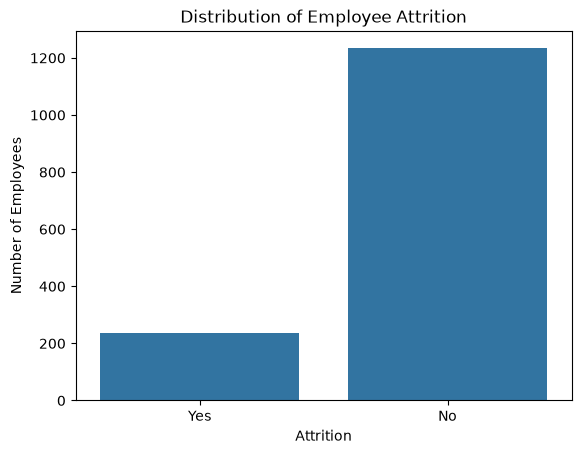

In [15]:
sns.countplot(data= df, x= 'Attrition')
plt.title('Distribution of Employee Attrition')
plt.ylabel('Number of Employees')
plt.show()

**Here are the charts to visualize the distribution of each core variables against attrition**

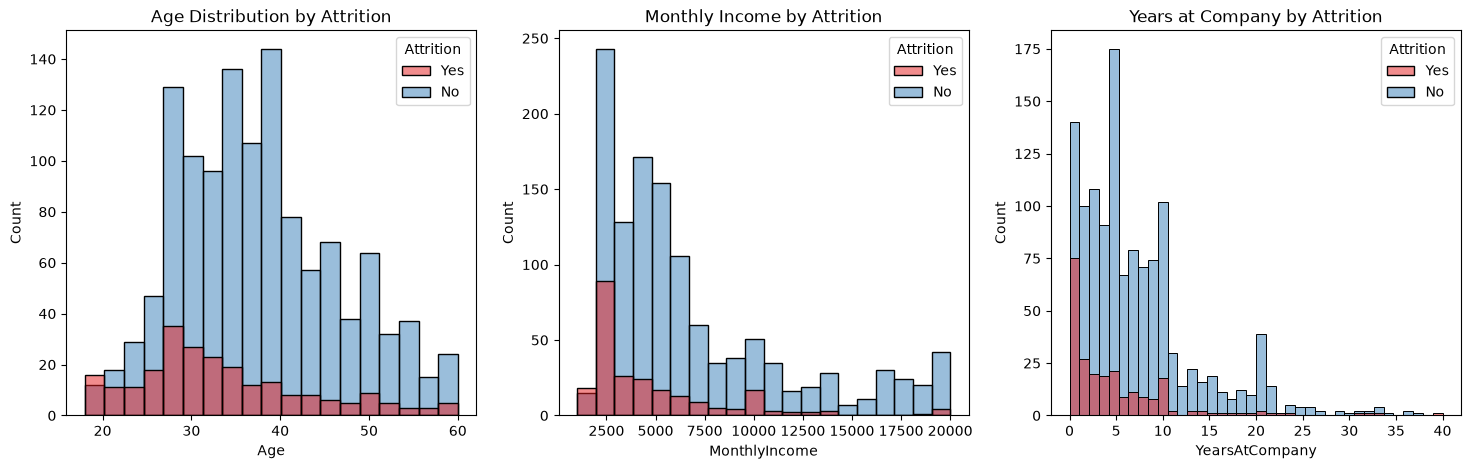

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# age 
sns.histplot(data=df, x='Age', hue='Attrition', ax=axes[0], palette='Set1')
axes[0].set_title('Age Distribution by Attrition')

# monthly income 
sns.histplot(data=df, x='MonthlyIncome', hue='Attrition', ax=axes[1], palette='Set1')
axes[1].set_title('Monthly Income by Attrition')

# years at company 
sns.histplot(data=df, x='YearsAtCompany', hue='Attrition', ax=axes[2], palette='Set1')
axes[2].set_title('Years at Company by Attrition')

plt.show()

### Data Cleaning: Finding columns that add no statistical values ###

**We can see that EmployeeNumber is just a column with employee's ID, we will not need this in the algorithm**

In [4]:
single_value_cols = df.columns[df.nunique() == 1]

print("Columns with only one unique value:", single_value_cols)

Columns with only one unique value: Index(['EmployeeCount', 'Over18', 'StandardHours'], dtype='str')


In [5]:
columns_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']

df_clean = df.drop(columns = columns_to_drop).copy()

display(df_clean)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,3,Male,...,3,3,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,4,Male,...,3,1,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,2,Male,...,4,2,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,4,Male,...,3,4,0,17,3,2,9,6,0,8


## Step 2: Data Preparation and Normalisation

### Now we are going to apply One-hot encoding to the 'textual' variables so that they can be understood by machine learning ###

**Note that we will drop 'Attrition' out because it is textual and also we don't need them later, so keeping them before one-hot encoding is redundant**



In [54]:
target = df_clean['Attrition']
features = df_clean.drop(columns= ['Attrition'])

categorical_columns = features.select_dtypes(include= ['string']).columns
print(f"Categorical columns to encode: {list(categorical_columns)}")

Categorical columns to encode: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [55]:
features_encoded = pd.get_dummies(features, columns= categorical_columns, drop_first= True)

print(f"\nDataset before encoding: {features.shape}")
print(f"Dataset after encoding: {features_encoded.shape}")

display(features_encoded.head())


Dataset before encoding: (1470, 30)
Dataset after encoding: (1470, 44)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1102,1,2,2,94,3,2,4,5993,...,False,False,False,False,False,True,False,False,True,True
1,49,279,8,1,3,61,2,2,2,5130,...,False,False,False,False,True,False,False,True,False,False
2,37,1373,2,2,4,92,2,1,3,2090,...,True,False,False,False,False,False,False,False,True,True
3,33,1392,3,4,4,56,3,1,3,2909,...,False,False,False,False,True,False,False,True,False,True
4,27,591,2,1,1,40,3,1,2,3468,...,True,False,False,False,False,False,False,True,False,False


### Next step we are going to use StandardScaler to normalize the data ###

**Why do we need normalization?** 

Because K-Means clustering relies on Euclidean distance to measure similarity between data points 

Without scaling, a feature with large numbers like MonthlyIncome ($15,000) will overpower a feature with small numbers like YearsAtCompany (5 years) simply because the raw numbers are bigger.    

In [57]:
from sklearn.preprocessing import StandardScaler

# find the columns that need scaling
numerical_columns = features.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()
features_encoded[numerical_columns] = scaler.fit_transform(features_encoded[numerical_columns])

display(features_encoded[numerical_columns].head())

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,0.446350,0.742527,-1.010909,-0.891688,-0.660531,1.383138,0.379672,-0.057788,1.153254,-0.108350,...,-0.426230,-1.584178,-0.932014,-0.421642,-2.171982,-2.493820,-0.164613,-0.063296,-0.679146,0.245834
1,1.322365,-1.297775,-0.147150,-1.868426,0.254625,-0.240677,-1.026167,-0.057788,-0.660853,-0.291719,...,2.346151,1.191438,0.241988,-0.164511,0.155707,0.338096,0.488508,0.764998,-0.368715,0.806541
2,0.008343,1.414363,-0.887515,-0.891688,1.169781,1.284725,-1.026167,-0.961486,0.246200,-0.937654,...,-0.426230,-0.658973,-0.932014,-0.550208,0.155707,0.338096,-1.144294,-1.167687,-0.679146,-1.155935
3,-0.429664,1.461466,-0.764121,1.061787,1.169781,-0.486709,0.379672,-0.961486,0.246200,-0.763634,...,-0.426230,0.266233,-0.932014,-0.421642,0.155707,0.338096,0.161947,0.764998,0.252146,-1.155935
4,-1.086676,-0.524295,-0.887515,-1.868426,-1.575686,-1.274014,0.379672,-0.961486,-0.660853,-0.644858,...,-0.426230,1.191438,0.241988,-0.678774,0.155707,0.338096,-0.817734,-0.615492,-0.058285,-0.595227


## Step 3: Significance Testing

### Hypothesis ###

**Null Hypothesis:** There is no statistically significant difference in Monthly Income of employees who left the company compared to those who stayed. (Any observed difference is by chance).

**Alternative Hypothesis:** There is a statistically significant difference in Monthly Income between employees who left and those who stayed. (The office rumour is real).

In [60]:
from scipy import stats

#isolate the MonthlyIncome feature
income_left = df_clean[df_clean['Attrition'] == 'Yes']['MonthlyIncome']
income_stayed = df_clean[df_clean['Attrition'] == 'No']['MonthlyIncome']

# execute Welchs t-test 
results = stats.ttest_ind(income_left, income_stayed, equal_var=False)

t_stats = results.statistic
p_value = results.pvalue

print(f"T-statistic: {t_stats.round(4):}")
print(f"P-value: {p_value.round(4):}")

T-statistic: -7.4826
P-value: 0.0


### Intepretations of the results ###

**The P-Value:** Because 0 is below the industry standard threshold - 0.05, we can reject the null hypothesis. This proves mathematically that the salary gap did not happen by random chance.

**The T-Statistic:** The negative number tells us the mean MonthlyIncome of the 1st group is less than the 2nd group. It confirms that the first group (people who left) makes less money than the second group (people who stayed).

The data supports the office rumour. There is a statistically significant pay gap driving employee turnover, with people leaving the company earning notably less than people who stay. 

## Step 4: Unsupervised Learning for Clustering

### To run a benchmark model, we are going to need to find the optimal K by using Elbow Method ###

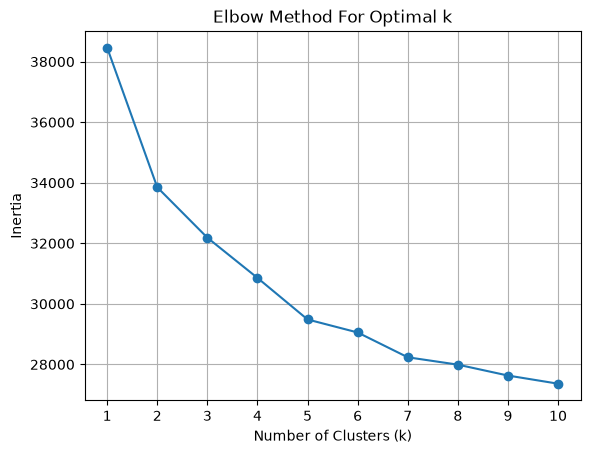

In [64]:
from sklearn.cluster import KMeans

inertia_values = []

for k in range(1, 11):

    kmeans = KMeans(n_clusters= k, random_state= 42, n_init= 'auto')
    kmeans.fit_predict(features_encoded)
    inertia_values.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia_values, marker='o')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**From here, we can see that the 'elbow' is at K=5 where the line suddenly flattens out and the returns start to diminish**

In [67]:
from sklearn.metrics import silhouette_score
k = 5

kmeans_benchmark = KMeans(n_clusters= k, random_state= 42, n_init= 'auto')
benchmark_labels = kmeans_benchmark.fit_predict(features_encoded)

benchmark_inertia = kmeans_benchmark.inertia_
benchmark_silhouette = silhouette_score(features_encoded, benchmark_labels)

print("--- Benchmark Model ---")

print(f"Intra-Cluster Cohesion (Inertia): {benchmark_inertia}")
print(f"Inter-Cluster Separation (Silhouette Score): {benchmark_silhouette}")

--- Benchmark Model ---
Intra-Cluster Cohesion (Inertia): 29484.939229200074
Inter-Cluster Separation (Silhouette Score): 0.08837315691796595


### Now we are going to reduce the "noise" by applying PCA ###


In [68]:
from sklearn.decomposition import PCA

# retaining 90% of the original statistical variance
pca = PCA(n_components=0.90, random_state=42)

# apply 
features_pca = pca.fit_transform(features_encoded)

# verify
print(f"Original number: {features_encoded.shape[1]}")
print(f"Reduced number of Principal Components: {features_pca.shape[1]}")

Original number of features: 44
Reduced number of Principal Components: 21


In [70]:
# execute k-means on the principal components
kmeans_pca = KMeans(n_clusters= 5, random_state= 42, n_init= 'auto')
pca_labels = kmeans_pca.fit_predict(features_pca)

# calculate the metrics 
pca_inertia = kmeans_pca.inertia_
pca_silhouette = silhouette_score(features_pca, pca_labels)

print("--- PCA Model ---")
print(f"Intra-Cluster Cohesion (Inertia): {pca_inertia}")
print(f"Inter-Cluster Separation (Silhouette Score): {pca_silhouette}")

--- PCA Model ---
Intra-Cluster Cohesion (Inertia): 26492.468927817798
Inter-Cluster Separation (Silhouette Score): 0.06844760917282387


### Interpretations ###

**1. Intra-Cluster Cohesion (Inertia) — Improved**

**Benchmark:** 29,484.94

**PCA-Reduced:** 26,492.47

The nertia dropped by roughly 3,000 points. 

Because lower inertia means tighter clusters, PCA improved the cohesion of employee personas. 

By removing 10% of "noise" data, we allowed k-means to pull the employees in each group much closer to their centroids.

**2. Inter-Cluster Separation (Silhouette Score) —  Worsened**

**Benchmark:** 0.0884

**PCA-Reduced:** 0.0684

The silhouette score dropped closer to zero. 

This means that while the clusters became tighter internally, the physical boundaries between them became more blurred or overlapping. 

This is consequence of PCA, when we removed "noise" data to compress the dataset, we lose the some data that were keeping the clusters distinct from one another.

## Step 5: Reporting ##